# Grad-CAM لنموذج Stage 2 (v2) على الـ hold-out النضيف
شغّلي الخلية ولازم تظهر دقة 84.16%.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
حجم الـ hold-out: 101
دقة الـ hold-out = 84.16%  (المفروض 84.16%)


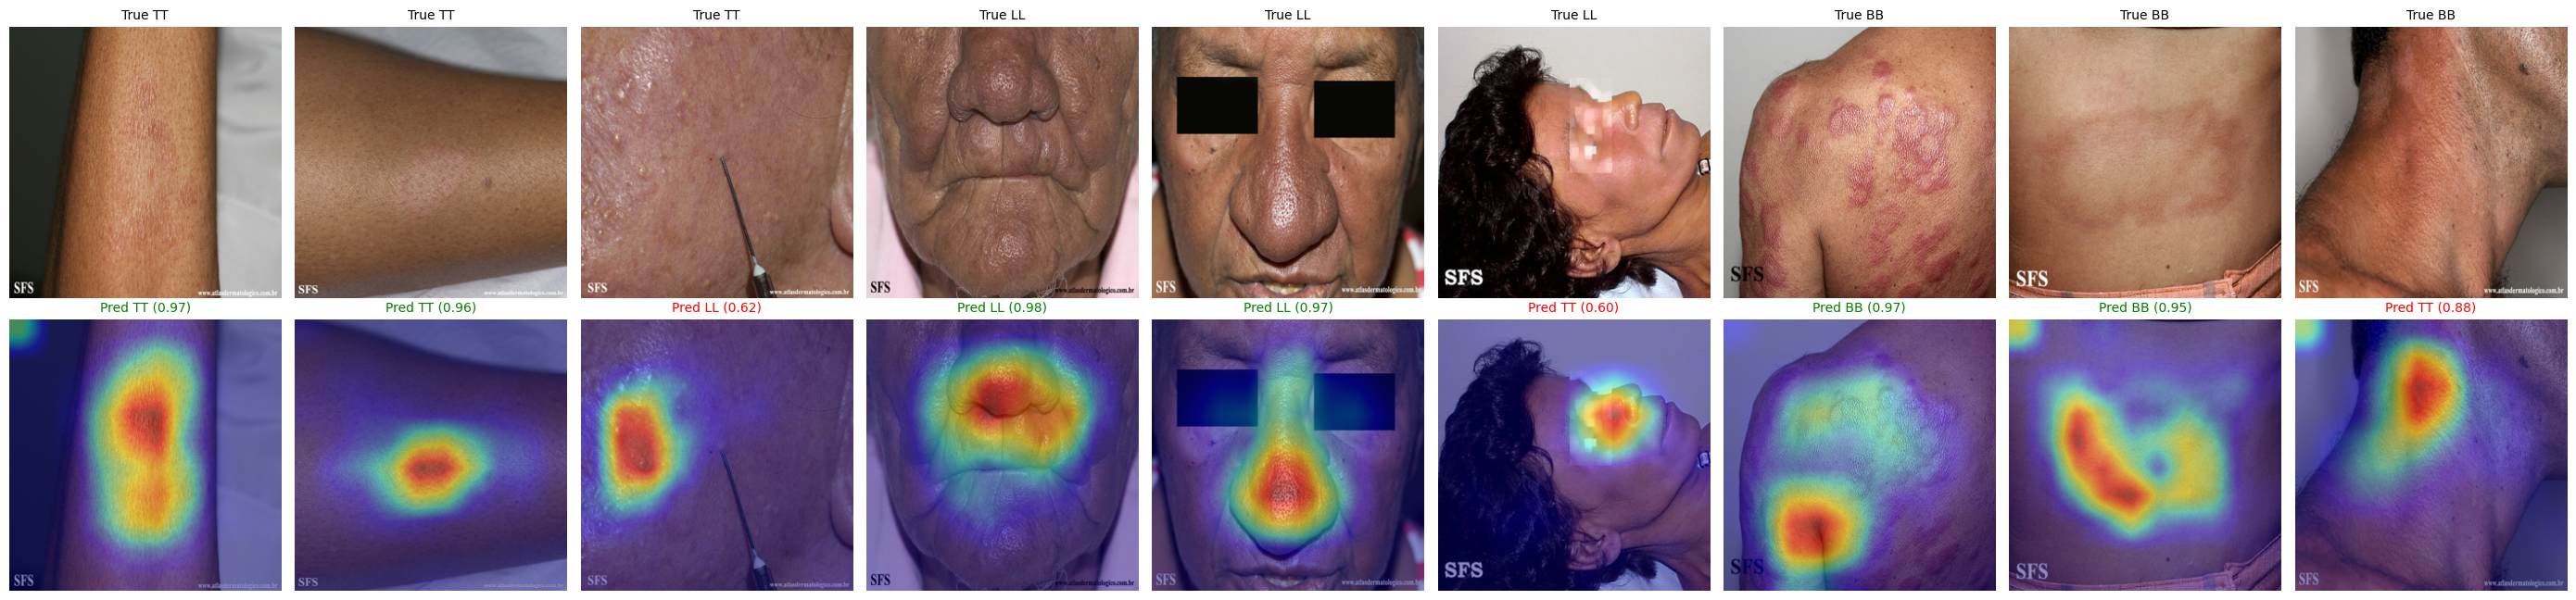

اتحفظت في: /content/drive/MyDrive/skin_disease_project/stage2_leprosy_subtype_v2/plots/gradcam_stage2_v2_holdout.png
  correct img_228_2.jpg Leprosy Tuberculoid -> Leprosy Tuberculoid
  correct img_158_2.jpg Leprosy Tuberculoid -> Leprosy Tuberculoid
  error img_152_2.jpg Leprosy Tuberculoid -> Leprosy Lepromatous
  correct img_166.jpg Leprosy Lepromatous -> Leprosy Lepromatous
  correct img_183.jpg Leprosy Lepromatous -> Leprosy Lepromatous
  error 3367.jpg Leprosy Lepromatous -> Leprosy Tuberculoid
  correct 3335.jpg Leprosy Borderline -> Leprosy Borderline
  correct 3343.jpg Leprosy Borderline -> Leprosy Borderline
  error img_129_2.jpg Leprosy Borderline -> Leprosy Tuberculoid


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import models, transforms
from PIL import Image
from scipy.ndimage import gaussian_filter

PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"
CKPT = f"{PROJECT_DIR}/stage2_leprosy_subtype_v2/checkpoints/imagenet_foldFINAL_best.pt"
SPLIT = "/content/drive/MyDrive/stage2_split_v2.csv"
OUT = f"{PROJECT_DIR}/stage2_leprosy_subtype_v2/plots"; os.makedirs(OUT, exist_ok=True)
CLASSES = ["Leprosy Tuberculoid", "Leprosy Lepromatous", "Leprosy Borderline"]
SHORT = {"Leprosy Tuberculoid": "TT", "Leprosy Lepromatous": "LL", "Leprosy Borderline": "BB"}
IMG = 300
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert os.path.exists(CKPT), "الـ checkpoint مش موجود"

m = models.efficientnet_b3(weights=None)
m.classifier = nn.Sequential(nn.Dropout(p=0.4), nn.Linear(m.classifier[1].in_features, 3))
m.load_state_dict(torch.load(CKPT, map_location=dev)); m.to(dev).eval()

tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

df = pd.read_csv(SPLIT)
pcol = [c for c in df.columns if "path" in c.lower()][0]
ho = df[df.stage2_role == "holdout"].reset_index(drop=True)
print("حجم الـ hold-out:", len(ho))

store = {}
def fwd(mod, i, o):
    if o.requires_grad:
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
m.features[-1].register_forward_hook(fwd)

def cam_for(x, cls):
    m.zero_grad(); out = m(x); out[0, cls].backward()
    a, g = store["a"][0].detach(), store["g"][0].detach()
    cam = torch.relu((g.mean(dim=(1, 2))[:, None, None] * a).sum(0))
    cam = (cam - cam.min()) / (cam.max() + 1e-8)
    return cam.cpu().numpy(), out.detach()

def overlay(img, cam, alpha=0.45):
    base = np.array(img.resize((IMG, IMG))).astype(np.float32) / 255
    c = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((IMG, IMG), Image.BILINEAR)).astype(np.float32) / 255
    c = gaussian_filter(c, 3); c = (c - c.min()) / (c.max() + 1e-8)
    heat = plt.get_cmap("jet")(c)[..., :3]
    return np.clip((1 - alpha) * base + alpha * heat, 0, 1)

rows = []
for i, r in ho.iterrows():
    img = Image.open(r[pcol]).convert("RGB")
    x = tf(img).unsqueeze(0).to(dev)
    with torch.no_grad(): p = F.softmax(m(x), 1)[0].cpu().numpy()
    rows.append((r[pcol], r["cls"], CLASSES[int(p.argmax())], p))
acc = np.mean([t == q for _, t, q, _ in rows])
print(f"دقة الـ hold-out = {acc*100:.2f}%  (المفروض 84.16%)")
assert abs(acc - 0.8416) < 0.005, "الدقة مش مطابقة - ده مش نفس النموذج!"

sel = []
for c in CLASSES:
    ok = sorted([r for r in rows if r[1] == c and r[2] == c], key=lambda r: -r[3][CLASSES.index(c)])[:2]
    bad = sorted([r for r in rows if r[1] == c and r[2] != c], key=lambda r: -r[3].max())[:1]
    sel += [(r, "correct") for r in ok] + [(r, "error") for r in bad]

fig, ax = plt.subplots(2, len(sel), figsize=(3.1 * len(sel), 6.6))
for j, ((path, t, q, p), kind) in enumerate(sel):
    img = Image.open(path).convert("RGB")
    x = tf(img).unsqueeze(0).to(dev).requires_grad_(True)
    cam, _ = cam_for(x, CLASSES.index(q))
    ax[0, j].imshow(img.resize((IMG, IMG))); ax[1, j].imshow(overlay(img, cam))
    ax[0, j].set_title(f"True {SHORT[t]}", fontsize=10)
    ax[1, j].set_title(f"Pred {SHORT[q]} ({p.max():.2f})", fontsize=10,
                       color="green" if kind == "correct" else "red")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout()
fp = f"{OUT}/gradcam_stage2_v2_holdout.png"
plt.savefig(fp, dpi=300, bbox_inches="tight"); plt.show()
print("اتحفظت في:", fp)
for r, k in sel: print(" ", k, os.path.basename(r[0]), r[1], "->", r[2])

from google.colab import files; files.download(fp)